# Классификация текстур CUReT

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F 
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, Dataset, DataLoader
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

Датасет содержит 61 класс текстур, по 92 изображения в каждом классе. Для каждого класса первые 46 изображений используются для обучения модели, оставшиеся 46 — для тестирования. Цель — достигнуть точности классификации не ниже 95%.

In [3]:
DATASET_ROOT = "curetcol"
NUM_CLASSES = 61
IMAGES_PER_CLASS = 92
TRAIN_PER_CLASS = 46

In [4]:
def load_and_preprocess_image(path):
    img = Image.open(path).convert("L")  # grayscale
    w, h = img.size
    img = img.resize((w // 2, h // 2), Image.BILINEAR)
    return np.array(img, dtype=np.float32)

Все изображения предварительно приводятся к оттенкам серого (grayscale), так как использование одного канала снижает размерность данных и вычислительную сложность модели.

После этого изображения уменьшаются в два раза по ширине и высоте, что позволяет сократить объём памяти и ускорить обучение нейронной сети без существенной потери информативности текстурных признаков.

In [5]:
X_train, y_train = [], []
X_test, y_test = [], []

class_folders = sorted(os.listdir(DATASET_ROOT))

for class_idx, class_name in enumerate(tqdm(class_folders)):
    class_path = os.path.join(DATASET_ROOT, class_name)
    image_files = sorted(os.listdir(class_path))

    for i, img_name in enumerate(image_files):
        img_path = os.path.join(class_path, img_name)
        img = load_and_preprocess_image(img_path)

        if i < TRAIN_PER_CLASS:
            X_train.append(img)
            y_train.append(class_idx)
        else:
            X_test.append(img)
            y_test.append(class_idx)

100%|██████████████████████████████████████████████████████████████████████████████████| 61/61 [00:10<00:00,  6.05it/s]


Значения пикселей нормализуются в диапазон [0, 1] путём деления на 255. Это улучшает численную стабильность обучения и ускоряет сходимость оптимизационного алгоритма.

In [6]:
X_train = np.stack(X_train)
X_test = np.stack(X_test)

X_train = X_train / 255.0
X_test = X_test / 255.0

y_train = np.array(y_train)
y_test = np.array(y_test)

print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (2806, 100, 100) (2806,)
Test : (2806, 100, 100) (2806,)


Посмотрим на выборку текстур из 0 класса, чтобы убедиться, что все действия до были выполнены корректно. 

In [7]:
def show_train_images_of_class(X_train, y_train, class_id, max_images=12):
    idxs = np.where(y_train == class_id)[0][:max_images]

    n = len(idxs)
    cols = min(6, n)
    rows = (n + cols - 1) // cols

    plt.figure(figsize=(2.5 * cols, 2.5 * rows))
    for i, idx in enumerate(idxs):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(X_train[idx], cmap="gray")
        plt.axis("off")
        plt.title(f"img {i}")

    plt.suptitle(f"Class {class_id} (train)", fontsize=14)
    plt.show()

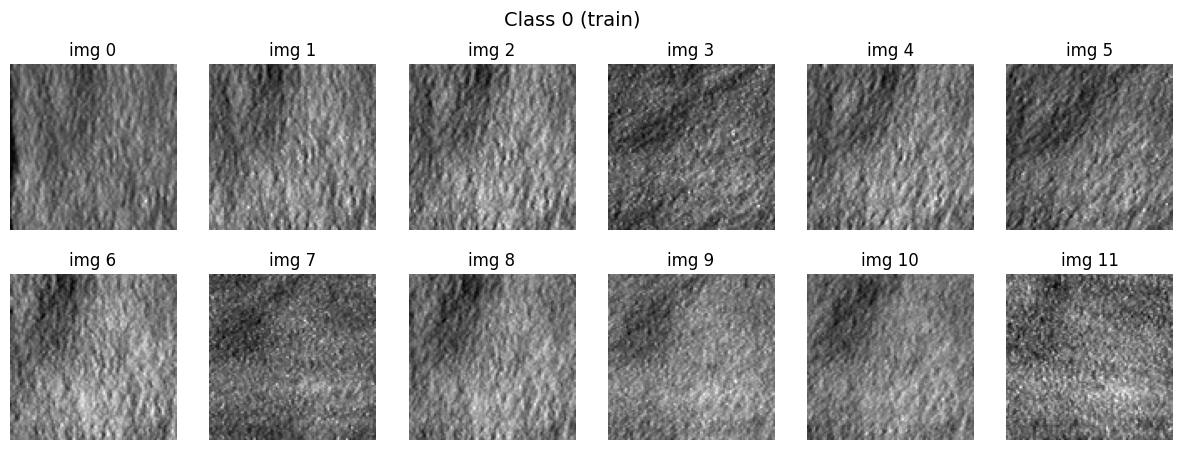

In [8]:
show_train_images_of_class(X_train, y_train, class_id=0)

Для обучения нейронной сети данные преобразуются в тензоры PyTorch. Добавляется размерность канала (1 канал для чб изображений), после чего формируются объекты TensorDataset и DataLoader.

In [9]:
X_train_tensor = torch.from_numpy(X_train).unsqueeze(1).float()  # [2806, 1, 100, 100]
X_test_tensor = torch.from_numpy(X_test).unsqueeze(1).float()    # [2806, 1, 100, 100]
y_train_tensor = torch.from_numpy(y_train).long()                # [2806]
y_test_tensor = torch.from_numpy(y_test).long()                  # [2806]

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)


batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=11,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=11,
    pin_memory=True
)

#print(f"Тип данных: {type(X_train_tensor)}")  # torch.Tensor
#print(f"Размерность: {X_train_tensor.shape}")  # torch.Size([2806, 1, 100, 100])

## Aрхитектуры сети TextureNetV2

Создадим сверточную нейронную сеть TextureNetV2, состоящую из четырёх последовательных сверточных блоков и полносвязного классификатора.

Каждый сверточный блок имеет одинаковую структуру и включает две свёртки, нормализацию, нелинейность, регуляризацию и операцию подвыборки.

Архитектура сети имеет следующий вид:

#### Сверточная часть

1. **Первый сверточный блок**

   * Свёрточный слой с **64 каналами**, размер ядра **3×3**, padding = 1;
   * Batch Normalization;
   * Функция активации **ReLU**;
   * Свёрточный слой с **64 каналами**, размер ядра **3×3**, padding = 1;
   * Batch Normalization;
   * Функция активации **ReLU**;
   * Dropout2D с вероятностью 0.1;
   * MaxPooling с размером окна **2×2**.

2. **Второй сверточный блок**

   * Свёрточный слой с **128 каналами**, размер ядра **3×3**, padding = 1;
   * Batch Normalization;
   * Функция активации **ReLU**;
   * Свёрточный слой с **128 каналами**, размер ядра **3×3**, padding = 1;
   * Batch Normalization;
   * Функция активации **ReLU**;
   * Dropout2D с вероятностью 0.1;
   * MaxPooling с размером окна **2×2**.

3. **Третий сверточный блок**

   * Свёрточный слой с **256 каналами**, размер ядра **3×3**, padding = 1;
   * Batch Normalization;
   * Функция активации **ReLU**;
   * Свёрточный слой с **256 каналами**, размер ядра **3×3**, padding = 1;
   * Batch Normalization;
   * Функция активации **ReLU**;
   * Dropout2D с вероятностью 0.1;
   * MaxPooling с размером окна **2×2**.

4. **Четвёртый сверточный блок**

   * Свёрточный слой с **512 каналами**, размер ядра **3×3**, padding = 1;
   * Batch Normalization;
   * Функция активации **ReLU**;
   * Свёрточный слой с **512 каналами**, размер ядра **3×3**, padding = 1;
   * Batch Normalization;
   * Функция активации **ReLU**;
   * Dropout2D с вероятностью 0.1;
   * MaxPooling с размером окна **2×2**.


5. **Global Average Pooling**

#### Полносвязная часть (классификатор)

6. **Полносвязный слой**

   * Линейный слой с **256 нейронами**;
   * Функция активации **ReLU**;
   * Dropout с вероятностью 0.15.

7. **Выходной слой**

   * Линейный слой с **61 нейроном**, соответствующим числу классов текстур.



In [10]:
class TextureNetV2(nn.Module):
    def __init__(self, num_classes=61):
        super().__init__()
        def conv_block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(),
                nn.Conv2d(out_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(),
                nn.Dropout2d(0.1),
                nn.MaxPool2d(2)
            )

        self.stage1 = conv_block(1, 64)
        self.stage2 = conv_block(64, 128)
        self.stage3 = conv_block(128, 256)
        self.stage4 = conv_block(256, 512)

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.gap(x)
        x = x.flatten(1)
        return self.fc(x)

В качестве функции потерь используется кросс-энтропия с label smoothing. Это позволяет снизить переобучение модели и улучшить обобщающую способность при большом числе классов.

Для обучения используется оптимизатор AdamW, который сочетает адаптивную настройку скорости обучения с корректной L2-регуляризацией весов. Этот оптимизатор даёт стабильное обучение.

Скорость обучения изменяется по функции косинуса с помощью CosineAnnealingLR, что позволяет постепенно уменьшать шаг оптимизации и повышает качество финального решения.

In [21]:
model = TextureNetV2(num_classes=61).cuda()

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
#scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=100, gamma=0.1)

In [12]:
def train_epoch(model, loader):
    model.train()
    correct, total = 0, 0
    total_loss = 0.0

    for x, y in loader:
        x, y = x.cuda(), y.cuda()

        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * y.size(0)

        pred = out.argmax(1)
        correct += (pred == y).sum().item()
        total += y.size(0)

    avg_loss = total_loss / total
    acc = correct / total

    return avg_loss, acc

In [13]:
def eval_epoch(model, loader):
    model.eval()
    correct, total = 0, 0
    total_loss = 0.0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.cuda(), y.cuda()
            out = model(x)
            loss = criterion(out, y)

            total_loss += loss.item() * y.size(0)

            pred = out.argmax(1)
            correct += (pred == y).sum().item()
            total += y.size(0)

    avg_loss = total_loss / total
    acc = correct / total

    return avg_loss, acc

## Обучение модели

Обучение модели проводилось в течение 225 эпох на устройстве **NVIDIA GeForce RTX 3050 8 Gb**. На каждой эпохе вычислялись значения функции потерь и точности на обучающей выборке.

Модель обучилась за **70 минут**. 

In [22]:
epoch = 225
with tqdm(range(1, epoch + 1), desc="Training", unit="epoch") as pbar:
    for epoch in pbar:
        train_loss, train_acc = train_epoch(model, train_loader)
        test_loss, test_acc = eval_epoch(model, test_loader)

        scheduler.step()
        print(
           f"Epoch {epoch:03d} | "
           f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
           f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f} | "
        )
        
        pbar.set_postfix({
            "epoch": epoch,
            "train_loss": f"{train_loss:.4f}",
            "train_acc": f"{train_acc:.3f}",
            #"test_acc": f"{test_acc:.3f}"
        })

Training:   0%|                      | 1/225 [00:18<1:10:40, 18.93s/epoch, epoch=1, train_loss=3.6908, train_acc=0.081]

Epoch 001 | Train Loss: 3.6908, Train Acc: 0.0809 | Test Loss: 3.3540, Test Acc: 0.1611 | 


Training:   1%|▏                     | 2/225 [00:37<1:09:34, 18.72s/epoch, epoch=2, train_loss=3.0926, train_acc=0.168]

Epoch 002 | Train Loss: 3.0926, Train Acc: 0.1679 | Test Loss: 2.9704, Test Acc: 0.1903 | 


Training:   1%|▎                     | 3/225 [00:55<1:08:44, 18.58s/epoch, epoch=3, train_loss=2.7149, train_acc=0.242]

Epoch 003 | Train Loss: 2.7149, Train Acc: 0.2420 | Test Loss: 2.7550, Test Acc: 0.2516 | 


... (440 outputs left out)

Training: 100%|█████████████████▉| 224/225 [1:10:21<00:18, 18.87s/epoch, epoch=224, train_loss=0.4296, train_acc=1.000]

Epoch 224 | Train Loss: 0.4296, Train Acc: 1.0000 | Test Loss: 0.5990, Test Acc: 0.9526 | 


Training: 100%|██████████████████| 225/225 [1:10:40<00:00, 18.85s/epoch, epoch=225, train_loss=0.4304, train_acc=1.000]

Epoch 225 | Train Loss: 0.4304, Train Acc: 1.0000 | Test Loss: 0.5835, Test Acc: 0.9608 | 


In [23]:
final_test_loss, final_test_acc = eval_epoch(model, test_loader)

print(f"Test Loss    : {final_test_loss:.4f}")
print(f"Test Accuracy: {final_test_acc:.4f}")

torch.save({
    "epoch": epoch,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "test_loss": final_test_loss,
    "test_acc": final_test_acc
}, "final_model.pth")

Test Loss    : 0.5835
Test Accuracy: 0.9608


В результате обучения была достигнута точность классификации 96% на тестовой выборке, что соответствует требуемуму порогу в 95%.